# code_140 · Conditional adversarial fitting and rare-mode checks

**Book:** section 27.3. A self-contained generative-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_27_GUIDE.md), [run evidence](../CHAPTER_27_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_140).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3340;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3340


<a id="adversarial-contract"></a>
 ## A discriminator loss is not a distributional certificate
 Ninety generated buildings each provide twelve correlated sensor-summary records. Source60/development15/final15 buildings remain whole groups. A historical failure class c has prevalence0.1; its right-hand latent mode has probability0.1 versus0.5 for the ordinary class. Fit two-coordinate conditional generators using balanced class minibatches, preserving the distinction between a conditioning request and the actual population prior. Three fixed recipes get1,000 generator updates: ordinary logistic cGAN at0.001, aggressive generator rate0.03 with discriminator0.001, and WGAN-GP at0.001 with three critic updates per generator and penalty10. Common sixteen-direction development Wasserstein scores select checkpoints every100updates; all recipes remain. Bootstrap and fitted conditional Gaussian references receive the same generation and augmentation checks. This is an own small reference, not full CTGAN.


,model,best_generator_update,development_equal_condition_distance,generator_parameters,critic_parameters,critic_updates,generator_updates,generator_rate
0,Conditional GAN,1000,0.225695,1250,1217,1000,1000,0.001
1,Aggressive generator,800,0.669404,1250,1217,1000,1000,0.030
2,Wasserstein GP,600,0.591089,1250,1217,3000,1000,0.001


,model,condition,reference_records,generated_records,final_projected_Wasserstein,generated_positive_mode_fraction,reference_positive_mode_fraction
0,Bootstrap,0,168,1000,0.110766,0.495,0.488095
1,Bootstrap,1,12,1000,0.346345,0.212,0.166667
2,Conditional Gaussian,0,168,1000,0.247201,0.506,0.488095
3,Conditional Gaussian,1,12,1000,0.412132,0.238,0.166667
4,Conditional GAN,0,168,1000,0.189589,0.508,0.488095
5,Conditional GAN,1,12,1000,0.495924,0.258,0.166667
6,Aggressive generator,0,168,1000,0.907662,0.000,0.488095
7,Aggressive generator,1,12,1000,0.922056,0.000,0.166667
8,Wasserstein GP,0,168,1000,0.511125,0.653,0.488095
9,Wasserstein GP,1,12,1000,0.482397,0.347,0.166667


,training,training_records,training_failure_fraction,final_Brier,final_average_precision
0,Source only,720,0.083333,0.056078,0.279948
1,Bootstrap augmentation,1080,0.388889,0.117505,0.276906
2,Conditional Gaussian augmentation,1080,0.388889,0.117664,0.279041
3,Conditional GAN augmentation,1080,0.388889,0.114186,0.252925
4,Aggressive generator augmentation,1080,0.388889,0.078843,0.260496
5,Wasserstein GP augmentation,1080,0.388889,0.149402,0.279891


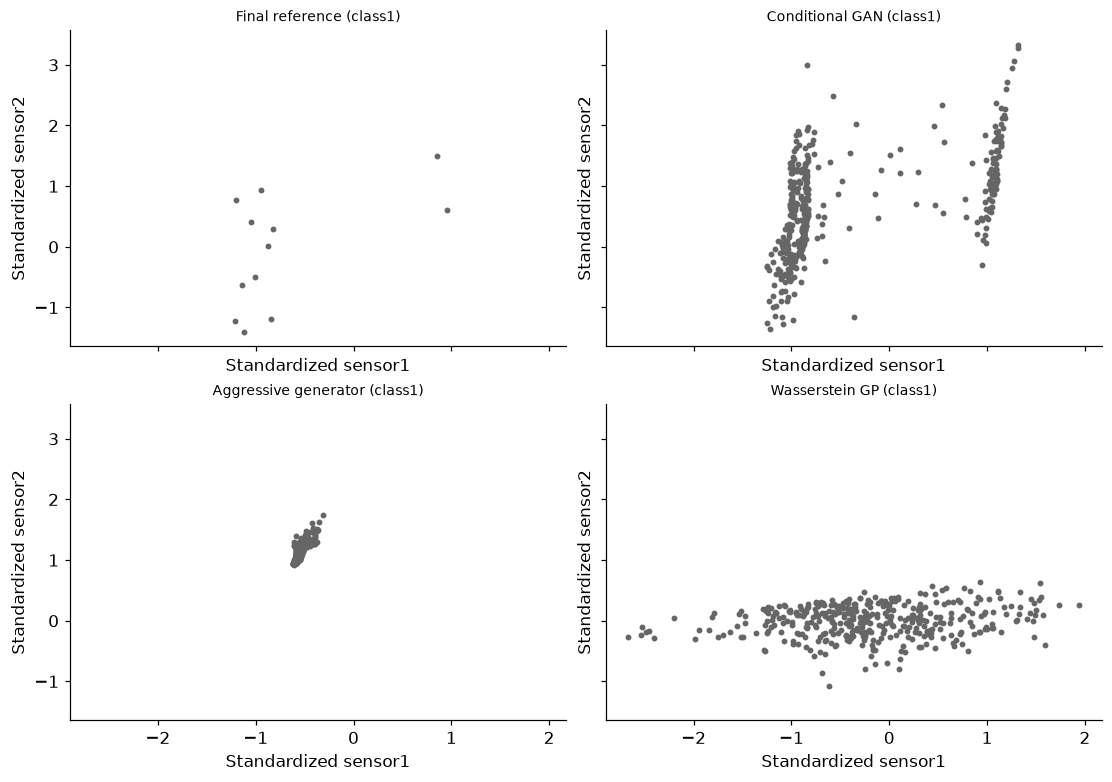

In [2]:
import copy
from scipy.stats import wasserstein_distance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss,average_precision_score
B,R=90,12;building=np.repeat(np.arange(B),R);label=rng.binomial(1,.1,B*R);mode=rng.binomial(1,np.where(label==1,.1,.5));x=(2*mode-1)*1.2+rng.normal(0,.2,B*R);y=.5*label+.35*np.sin(x)+rng.normal(0,.35,B*R)+rng.normal(0,.1,B)[building];raw=np.column_stack([x,y]);source=building<60;dev=(building>=60)&(building<75);final=building>=75;center=raw[source].mean(0);spread=raw[source].std(0);standard=(raw-center)/spread;X=torch.tensor(standard);C=torch.tensor(label[:,None]).double();source_indices={c:np.flatnonzero(source&(label==c)) for c in [0,1]};directions=np.column_stack([np.cos(np.arange(16)*np.pi/16),np.sin(np.arange(16)*np.pi/16)])
def distance(a,b):return float(np.mean([wasserstein_distance(a@v,b@v) for v in directions]))
def network(inputs,outputs):return nn.Sequential(nn.Linear(inputs,32),nn.LeakyReLU(.2),nn.Linear(32,32),nn.LeakyReLU(.2),nn.Linear(32,outputs))
class Generator(nn.Module):
    def __init__(self):super().__init__();self.net=network(3,2)
    def forward(self,z,c):return self.net(torch.cat([z,c],1))
batches=[]
for step in range(1000):batches.append([np.r_[rng.choice(source_indices[0],64),rng.choice(source_indices[1],64)] for j in range(3)])
latent=torch.tensor(rng.normal(size=(1000,128,2)));critic_latent=torch.tensor(rng.normal(size=(1000,3,128,2)));validation_noise=torch.tensor(rng.normal(size=(512,2)));balanced=torch.cat([torch.zeros((64,1)),torch.ones((64,1))]);models={};histories={};fit_rows=[]
for recipe,gen_rate,critic_steps,wasserstein in [('Conditional GAN',.001,1,False),('Aggressive generator',.03,1,False),('Wasserstein GP',.001,3,True)]:
    torch.manual_seed(SEED);G=Generator();D=network(3,1);go=torch.optim.Adam(G.parameters(),lr=gen_rate,betas=(.5,.9));do=torch.optim.Adam(D.parameters(),lr=.001,betas=(.5,.9));best=np.inf;history=[]
    for step in range(1000):
        for j in range(critic_steps):
            indices=torch.tensor(batches[step][j]);c=C[indices];real=X[indices];fake=G(critic_latent[step,j],c).detach();do.zero_grad();real_score=D(torch.cat([real,c],1));fake_score=D(torch.cat([fake,c],1))
            if wasserstein:
                # Use one convex weight per pair, shared by both endpoints.
                mixing=torch.rand((128,1));interpolation=(mixing*real+(1-mixing)*fake).requires_grad_(True);score=D(torch.cat([interpolation,c],1));gradient=torch.autograd.grad(score,interpolation,torch.ones_like(score),create_graph=True)[0];penalty=(gradient.norm(dim=1)-1).square().mean();dloss=fake_score.mean()-real_score.mean()+10*penalty
                if step==0 and j==0:
                    assert torch.all(interpolation>=torch.minimum(real,fake)-1e-12) and torch.all(interpolation<=torch.maximum(real,fake)+1e-12)
                    assert torch.isfinite(gradient).all() and gradient.shape==real.shape
            else:dloss=torch.nn.functional.binary_cross_entropy_with_logits(real_score,torch.ones_like(real_score))+torch.nn.functional.binary_cross_entropy_with_logits(fake_score,torch.zeros_like(fake_score))
            dloss.backward();do.step()
        go.zero_grad();fake=G(latent[step],balanced);score=D(torch.cat([fake,balanced],1));gloss=-score.mean() if wasserstein else torch.nn.functional.binary_cross_entropy_with_logits(score,torch.ones_like(score));gloss.backward();go.step()
        if (step+1)%100==0:
            with torch.no_grad():metrics=[distance(G(validation_noise,torch.full((512,1),float(c))).numpy(),standard[dev&(label==c)]) for c in [0,1]]
            development=float(np.mean(metrics));history.append([step+1,float(dloss.detach()),float(gloss.detach()),development])
            if development<best:best=development;state=copy.deepcopy(G.state_dict());best_step=step+1
    G.load_state_dict(state);models[recipe]=G;histories[recipe]=history;fit_rows.append({'model':recipe,'best_generator_update':best_step,'development_equal_condition_distance':best,'generator_parameters':sum(p.numel() for p in G.parameters()),'critic_parameters':sum(p.numel() for p in D.parameters()),'critic_updates':1000*critic_steps,'generator_updates':1000,'generator_rate':gen_rate})
generation={};rows=[]
for name in ['Bootstrap','Conditional Gaussian',*models]:
    generated=[]
    for c in [0,1]:
        if name=='Bootstrap':sample=standard[rng.choice(source_indices[c],1000)]
        elif name=='Conditional Gaussian':sample=rng.multivariate_normal(standard[source_indices[c]].mean(0),np.cov(standard[source_indices[c]].T),1000)
        else:
            with torch.no_grad():sample=models[name](torch.tensor(rng.normal(size=(1000,2))),torch.full((1000,1),float(c))).numpy()
        actual=standard[final&(label==c)];natural=sample*spread+center;rows.append({'model':name,'condition':c,'reference_records':len(actual),'generated_records':len(sample),'final_projected_Wasserstein':distance(sample,actual),'generated_positive_mode_fraction':float(np.mean(natural[:,0]>0)),'reference_positive_mode_fraction':float(np.mean(raw[final&(label==c),0]>0))});generated.append(sample)
    generation[name]=generated
utility=[];base=LogisticRegression(C=1,max_iter=500).fit(standard[source],label[source]);p=base.predict_proba(standard[final])[:,1];utility.append({'training':'Source only','training_records':int(source.sum()),'training_failure_fraction':float(label[source].mean()),'final_Brier':float(brier_score_loss(label[final],p)),'final_average_precision':float(average_precision_score(label[final],p))})
for name,samples in generation.items():
    # Exactly the same added class-one count; class-prior shift is part of this recipe.
    synthetic=samples[1][:360];aug_x=np.vstack([standard[source],synthetic]);aug_y=np.r_[label[source],np.ones(360)];classifier=LogisticRegression(C=1,max_iter=500).fit(aug_x,aug_y);p=classifier.predict_proba(standard[final])[:,1];utility.append({'training':name+' augmentation','training_records':len(aug_y),'training_failure_fraction':float(aug_y.mean()),'final_Brier':float(brier_score_loss(label[final],p)),'final_average_precision':float(average_precision_score(label[final],p))})
assert len(source_indices[1])>0 and len(np.unique(label[final]))==2
RESULTS.update(fitting=fit_rows,conditional_generation=rows,augmentation=utility,building_counts=[60,15,15],source_failure_records=len(source_indices[1]),final_failure_records=int((final&(label==1)).sum()),added_failure_records_per_recipe=360,development_directions=16);display(pd.DataFrame(fit_rows));display(pd.DataFrame(rows));display(pd.DataFrame(utility))
fig,axes=plt.subplots(2,2,figsize=(10,7),sharex=True,sharey=True);panels=[('Final reference',standard[final&(label==1)]),*[(name,generation[name][1]) for name in models]]
for ax,(name,sample) in zip(axes.ravel(),panels):ax.scatter(sample[:400,0],sample[:400,1],s=8,color='.4');ax.set(xlabel='Standardized sensor1',ylabel='Standardized sensor2',title=name+' (class1)')
plt.show()


<a id="adversarial-assessment"></a>
 ## Track modes, fitting dynamics and downstream use separately
 The aggressive learning-rate recipe changes optimization rather than the data-generating target. Critic/generator losses have recipe-specific meanings; an apparently low value does not establish conditional mode coverage. Checkpoints use a fixed development-noise panel and equal-condition distance, giving rare conditions explicit selection weight; the final cohort is untouched and its small class-one count remains visible. WGAN-GP uses a convex real/fake interpolation and the input gradient norm penalty, with three times as many critic updates as the logistic GAN. Bootstrap and Gaussian references remain. Added class-one records change the classifier's fitted class prior; Brier and average precision are reported separately rather than claiming augmentation improves calibration. Own continuous-summary cGAN/WGAN references do not implement CTGAN's complete mixed-type preprocessing and training recipe.


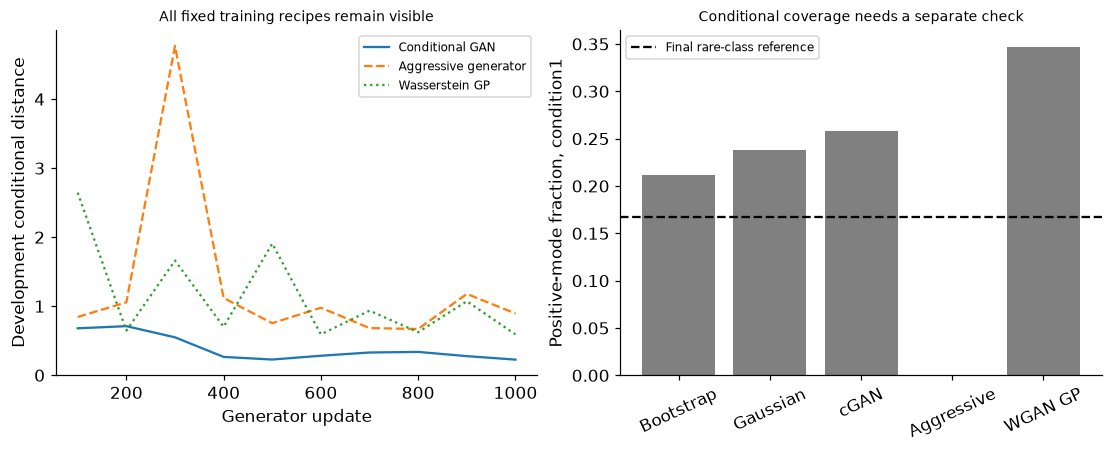

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for name,style in zip(histories,['-','--',':']):history=np.array(histories[name]);axes[0].plot(history[:,0],history[:,3],style,label=name)
axes[0].set(xlabel='Generator update',ylabel='Development conditional distance',title='All fixed training recipes remain visible');axes[0].legend(fontsize=8);names=list(generation);selected=[r for r in rows if r['condition']==1];axes[1].bar(range(len(names)),[r['generated_positive_mode_fraction'] for r in selected],color='.5');axes[1].axhline(selected[0]['reference_positive_mode_fraction'],color='black',linestyle='--',label='Final rare-class reference');axes[1].set(xticks=range(len(names)),xticklabels=['Bootstrap','Gaussian','cGAN','Aggressive','WGAN GP'],ylabel='Positive-mode fraction, condition1',title='Conditional coverage needs a separate check');axes[1].tick_params(axis='x',labelrotation=25);axes[1].legend(fontsize=8);plt.show()
assert all(np.isfinite(r['final_projected_Wasserstein']) for r in rows) and len(utility)==6


In [4]:
summary={'example_id':'code_140','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual conditional GAN and Wasserstein gradient penalty', 'controlled aggressive generator candidate', 'development selected generative checkpoints', 'conditional mode coverage and resampling references', 'actual rare-class augmentation assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual conditional GAN and Wasserstein gradient penalty", "controlled aggressive generator candidate", "development selected generative checkpoints", "conditional mode coverage and resampling references", "actual rare-class augmentation assessment"], "elapsed_seconds": 3.16, "example_id": "code_140", "hardware": "Darwin arm64 CPU", "results": {"added_failure_records_per_recipe": 360, "augmentation": [{"final_Brier": 0.056077619410624065, "final_average_precision": 0.27994768417810034, "training": "Source only", "training_failure_fraction": 0.08333333333333333, "training_records": 720}, {"final_Brier": 0.11750473692059961, "final_average_precision": 0.27690573886884445, "training": "Bootstrap augmentation", "training_failure_fraction": 0.3888888888888889, "training_records": 1080}, {"final_Brier": 0.11766374009761718, "final_average_precision": 0.2790408553945492, "training": "Conditional Gaussian augmentation", "training_failure_fracti